# 用 python-pptx 组合：把组件拼成论文里的图

这是组会讲的第 4 步，接在 `Fig1-3小组件画法.ipynb` 后面：组件画好以后，用 python-pptx 把它们放回一页和论文图一样大的 PPT 里，框、标题、编号、箭头用 PPT 自己的形状画。生成的 .pptx 用 PowerPoint 或 WPS 打开，每个框、每行字都还能改，改完导出 PDF 就能放进论文。

- 需要 python-pptx（`pip install python-pptx`），预览那一格还要 matplotlib。
- 组件图片用的是 `out/` 里的 PNG，先运行过 `Fig1-3小组件画法.ipynb` 才有（这个文件夹里已经有一份）。
- 生成的文件也放在 `out/`：`最小例子.pptx`、`Fig3_组合.pptx`、`一页幻灯片.pptx`。
- 坐标单位都是毫米，原点在页面左上角，y 往下。

## 1. 最小例子：一个框、一行字、一条连线、一个组件

PPT 第 24 页那段代码。页面设成论文里这张图的大小，字号就是印出来的字号。

In [1]:
from pptx import Presentation
from pptx.dml.color import RGBColor
from pptx.enum.shapes import MSO_CONNECTOR, MSO_SHAPE
from pptx.util import Mm, Pt

prs = Presentation()
prs.slide_width, prs.slide_height = Mm(190), Mm(116)    # 页面 = 论文里这张图的大小
s = prs.slides.add_slide(prs.slide_layouts[6])          # 空白页

box = s.shapes.add_shape(MSO_SHAPE.ROUNDED_RECTANGLE,   # ① 框：左、上、宽、高
                         Mm(145), Mm(56), Mm(39), Mm(8))
box.fill.solid(); box.fill.fore_color.rgb = RGBColor(255, 255, 255)
box.line.color.rgb = RGBColor(0xD0, 0x8A, 0x1E); box.line.width = Pt(0.6)

tb = s.shapes.add_textbox(Mm(145), Mm(56.5), Mm(39), Mm(4))   # ② 一行字
tb.text_frame.text = "Candidate batch"
tb.text_frame.paragraphs[0].runs[0].font.size = Pt(6.8)

s.shapes.add_connector(MSO_CONNECTOR.STRAIGHT,           # ③ 连线：起点、终点
                       Mm(164.5), Mm(52), Mm(164.5), Mm(55.5))
s.shapes.add_picture("out/fig3_10_surrogate_search.png", # ④ 组件
                     Mm(142.5), Mm(35.2), width=Mm(42))
prs.save("out/最小例子.pptx")
print("已保存 out/最小例子.pptx，页面上有", len(s.shapes), "个形状")

已保存 out/最小例子.pptx，页面上有 4 个形状


## 2. 把 Fig. 3 拼起来

页面和论文里的 Fig. 3 一样大（190.15 × 115.5 mm）。下面每一行就是页面上的一个形状，坐标、颜色、字号都取自论文 Fig. 3 的 PPT 母版；16 张组件图片放在它们在论文里的位置。

### 2.1 几个小函数

每个函数往页面上加一个 PPT 自己的形状，同时把它记进 `SHAPES`，最后画预览用。

- `box` 框（可以圆角、虚线、渐变）、`text` 一段字（可以带底色）、`arrow` 带箭头的线（两点是直线，多点是折线）、`badge` 带编号的小圆、`dot` 小圆点、`pic` 组件图片。
- `text` 里 `$…$` 中间按公式排：字母用斜体，`_` 是下标、`^` 是上标，`\bm{…}` 粗斜体、`\mathbf{…}` 粗正体。比如 `"Nodal adder signal $A_t$"`。

In [2]:
import re
import unicodedata

from lxml import etree
from pptx import Presentation
from pptx.dml.color import RGBColor
from pptx.enum.dml import MSO_LINE_DASH_STYLE
from pptx.enum.shapes import MSO_CONNECTOR, MSO_SHAPE
from pptx.enum.text import MSO_ANCHOR, MSO_AUTO_SIZE, PP_ALIGN
from pptx.oxml.ns import qn
from pptx.util import Mm, Pt

FONT, INK = "Times New Roman", "#1A1A1A"                       # 和论文正文一样用 Times
W, H = 190.15, 115.5                                            # 论文里 Fig. 3 的大小（mm）

prs = Presentation()
prs.slide_width, prs.slide_height = Mm(W), Mm(H)
slide = prs.slides.add_slide(prs.slide_layouts[6])
SHAPES = []                                                     # 加过的形状，预览用


def rgb(c):
    return RGBColor.from_string(c.lstrip("#").upper())


def stroke(shp, color, lw, dash=False):
    if color is None:
        shp.line.fill.background()
        return
    shp.line.color.rgb = rgb(color)
    shp.line.width = Pt(lw)
    if dash:
        shp.line.dash_style = MSO_LINE_DASH_STYLE.DASH


def box(x, y, w, h, fill=None, grad=None, line=None, lw=0.6, dash=False, r=0.0):
    """框。grad=(左上颜色, 右下颜色) 是 45° 的线性渐变；r 是圆角半径（mm）。"""
    shp = slide.shapes.add_shape(MSO_SHAPE.ROUNDED_RECTANGLE if r else MSO_SHAPE.RECTANGLE,
                                 Mm(x), Mm(y), Mm(w), Mm(h))
    if r:
        shp.adjustments[0] = r / min(w, h)
    if grad:                                                    # python-pptx 的渐变：两个色标
        shp.fill.gradient()
        shp.fill.gradient_angle = 315                           # 从左上到右下（python-pptx 按逆时针算角度）
        stops = shp.fill.gradient_stops
        stops[0].color.rgb, stops[0].position = rgb(grad[0]), 0.0
        stops[1].color.rgb, stops[1].position = rgb(grad[1]), 1.0
    elif fill:
        shp.fill.solid()
        shp.fill.fore_color.rgb = rgb(fill)
    else:
        shp.fill.background()
    stroke(shp, line, lw, dash)
    shp.shadow.inherit = False                                  # 不要默认的阴影
    SHAPES.append(dict(kind="box", x=x, y=y, w=w, h=h, fill=grad[1] if grad else fill, line=line, lw=lw,
                       dash=dash, r=r))
    return shp


STYLE_CMD = {"\\bm": (True, True), "\\mathbf": (True, False)}         # 命令 -> (粗体, 斜体)


def runs_of(label, bold):
    """把一段带 $…$ 的字拆成几段 (文字, 粗体, 斜体, 上下标)；上下标用 PowerPoint 的 baseline（±百分之几十）。"""
    out = []
    for k, part in enumerate(label.split("$")):
        if k % 2 == 0:                                          # 公式外：普通文字
            if part:
                out.append((part, bold, False, 0))
            continue
        i, base = 0, 0
        while i < len(part):                                    # 公式里：一个记号一个记号地读
            m = re.match(r"(\\bm|\\mathbf)\{([^}]*)\}|([_^])\{|([_^])(.)|\}|(.)", part[i:])
            i += m.end()
            if m.group(1):
                b, it = STYLE_CMD[m.group(1)]
                out.append((m.group(2), b, it, base))
            elif m.group(3):                                    # _{ 或 ^{ ：后面直到 } 都是下标/上标
                base = -25000 if m.group(3) == "_" else 30000
            elif m.group(4):                                    # _x 或 ^x：只有一个字符
                out.append((m.group(5), False, m.group(5).isalpha(), -25000 if m.group(4) == "_" else 30000))
            elif m.group(0) == "}":
                base = 0
            else:
                ch = m.group(6)
                if unicodedata.combining(ch) and out:           # 组合符号（比如 C̄ 上的横线）跟着前一个字
                    t, b, it, bs = out[-1]
                    out[-1] = (t + ch, b, it, bs)
                else:
                    out.append((ch, False, ch.isalpha(), base))
    merged = []
    for r in out:                                               # 格式相同的相邻几段合并
        if merged and merged[-1][1:] == r[1:]:
            merged[-1] = (merged[-1][0] + r[0],) + r[1:]
        else:
            merged.append(r)
    return merged


def text(x, y, w, label, size=6.8, bold=False, color=INK, align="l", bg=None):
    """一段字：左上角 (x, y)，宽 w（居中、右对齐时用到）；\n 换行。bg 是底色（压在线上的标注用白底）。"""
    n = label.count("\n") + 1
    tb = slide.shapes.add_textbox(Mm(x), Mm(y), Mm(w), Mm(n * size * 0.44 + 0.3))
    tf = tb.text_frame
    tf.margin_left = tf.margin_right = tf.margin_top = tf.margin_bottom = 0
    tf.word_wrap, tf.auto_size, tf.vertical_anchor = False, MSO_AUTO_SIZE.NONE, MSO_ANCHOR.TOP
    if bg:
        tb.fill.solid()
        tb.fill.fore_color.rgb = rgb(bg)
    for j, line in enumerate(label.split("\n")):
        p = tf.paragraphs[0] if j == 0 else tf.add_paragraph()
        p.alignment = {"l": PP_ALIGN.LEFT, "c": PP_ALIGN.CENTER, "r": PP_ALIGN.RIGHT}[align]
        for t, b, it, base in runs_of(line, bold):
            r = p.add_run()
            r.text = t
            r.font.name, r.font.size, r.font.bold, r.font.italic = FONT, Pt(size), b, it
            r.font.color.rgb = rgb(color)
            if base:
                r._r.get_or_add_rPr().set("baseline", str(base))
    SHAPES.append(dict(kind="text", x=x, y=y, w=w, label=label, size=size, bold=bold, color=color, align=align, bg=bg))
    return tb


def arrow(pts, color, lw=1.0, head=True):
    """带箭头的线：两个点是一条直线（连接线），多个点是折线（自由形状），箭头在最后一个点。"""
    E = lambda v: Mm(v)
    if len(pts) == 2:
        shp = slide.shapes.add_connector(MSO_CONNECTOR.STRAIGHT, E(pts[0][0]), E(pts[0][1]),
                                         E(pts[1][0]), E(pts[1][1]))
    else:
        fb = slide.shapes.build_freeform(E(pts[0][0]), E(pts[0][1]), scale=1.0)
        fb.add_line_segments([(E(px), E(py)) for px, py in pts[1:]], close=False)
        shp = fb.convert_to_shape()
        shp.fill.background()
    stroke(shp, color, lw)
    if head:                                                    # python-pptx 没有箭头的写法，直接改 XML
        tail = etree.SubElement(shp.line._get_or_add_ln(), qn("a:tailEnd"))
        tail.set("type", "triangle")
    shp.shadow.inherit = False
    SHAPES.append(dict(kind="arrow", pts=pts, color=color, lw=lw, head=head))
    return shp


def badge(n, cx, cy, d, color):
    """带编号的小圆：圆心 (cx, cy)，直径 d。"""
    shp = slide.shapes.add_shape(MSO_SHAPE.OVAL, Mm(cx - d / 2), Mm(cy - d / 2), Mm(d), Mm(d))
    shp.fill.solid()
    shp.fill.fore_color.rgb = rgb(color)
    shp.line.fill.background()
    shp.shadow.inherit = False
    tf = shp.text_frame
    tf.margin_left = tf.margin_right = tf.margin_top = tf.margin_bottom = 0
    tf.vertical_anchor, tf.word_wrap = MSO_ANCHOR.MIDDLE, False
    p = tf.paragraphs[0]
    p.alignment = PP_ALIGN.CENTER
    r = p.add_run()
    r.text = str(n)
    r.font.name, r.font.size, r.font.bold = FONT, Pt(6.6), True
    r.font.color.rgb = rgb("#FFFFFF")
    SHAPES.append(dict(kind="badge", n=n, cx=cx, cy=cy, d=d, color=color))
    return shp


def dot(cx, cy, d, color, line=None):
    shp = slide.shapes.add_shape(MSO_SHAPE.OVAL, Mm(cx - d / 2), Mm(cy - d / 2), Mm(d), Mm(d))
    shp.fill.solid()
    shp.fill.fore_color.rgb = rgb(color)
    stroke(shp, line, 0.4)
    shp.shadow.inherit = False
    SHAPES.append(dict(kind="dot", cx=cx, cy=cy, d=d, color=color, line=line))
    return shp


def pic(path, x, y, w):
    """组件图片：左上角 (x, y)，宽 w，高按图片比例。"""
    shp = slide.shapes.add_picture(path, Mm(x), Mm(y), width=Mm(w))
    SHAPES.append(dict(kind="pic", path=path, x=x, y=y, w=w))
    return shp

### 2.2 左栏：价格–响应接口

左边的大框、加价信号、三类聚合商、响应档案，加上 1、2 两步的编号和箭头。

In [3]:
box(0.83, 3.63, 50, 87, grad=('#FFFFFF', '#EDF0F4'), line="#8B909A", lw=0.75, r=2.5)
text(0.83, 4.97, 50, "Price–response interface", 9, bold=True, align="c")
text(2.83, 9.63, 40, "Nodal adder signal $A_t$", 7.3, bold=True)
pic("out/fig3_01_adder_signal.png", 3.68, 13.67, 39.96)               # ① 加价信号热力图板
arrow([(11.83, 30.03), (11.83, 35.23)], "#D08A1E", 1.1)
badge(1, 7.43, 32.63, 3.3, "#4D4D4D")
text(14.23, 31.23, 30, "Trial signals", 6.8, bold=True)
box(2.33, 35.63, 47, 33.6, fill="#FFFFFF", line="#8B909A", lw=0.6, dash=True, r=1.8)
text(4.33, 36.33, 43, "Private aggregators (price takers)", 7.3, bold=True)
pic("out/fig3_02_aggregator_ev.png", 3.81, 40.68, 43.98)              # ② 聚合商：电动汽车
pic("out/fig3_02_aggregator_ai.png", 3.85, 50.08, 43.98)              # ② 聚合商：算力
pic("out/fig3_02_aggregator_es.png", 3.85, 59.48, 43.98)              # ② 聚合商：储能
arrow([(11.83, 69.23), (11.83, 74.03)], "#4D4D4D", 1.1)
badge(2, 7.43, 71.63, 3.3, "#4D4D4D")
text(14.23, 70.33, 34, "Rolled-out responses", 6.8, bold=True)
pic("out/fig3_03_response_archive.png", 3.27, 75.23, 45.81)           # ③ 响应档案

### 2.3 中栏：灰箱组合

学到的响应（3）和已知的物理（4）两个虚线框，各放几个组件。

In [4]:
box(53.83, 3.63, 82, 87, grad=('#FFFFFF', '#EDF2F8'), line="#84A4CE", lw=0.75, r=2.5)
text(53.83, 4.53, 82, "Gray-box composition", 9, bold=True, align="c")
box(55.83, 10.13, 37.5, 79, grad=('#F4F8EF', '#EEF3EC'), line="#2B8A7A", lw=1, dash=True, r=2)
badge(3, 58.83, 13.03, 3.3, "#2B8A7A")
text(59.83, 11.23, 33.5, "Learned responses", 8, bold=True, align="c")
text(55.83, 17.26, 37.5, "One model per follower", 6.8, bold=True, align="c")
pic("out/fig3_04_learned_surface_ev.png", 57.83, 21.84, 32.98)        # ④ 响应曲面：电动汽车
text(60.03, 22.03, 14, "EV", 6.8, bold=True)
pic("out/fig3_04_learned_surface_ai.png", 57.83, 32.55, 32.98)        # ④ 响应曲面：算力
text(60.03, 32.73, 14, "Computing", 6.8, bold=True)
pic("out/fig3_04_learned_surface_es.png", 57.83, 43.22, 32.98)        # ④ 响应曲面：储能
text(60.03, 43.43, 14, "Storage", 6.8, bold=True)
text(57.43, 54.63, 34, "Random features", 7, bold=True)
pic("out/fig3_05_random_features.png", 57.45, 57.66, 34.97)           # ⑤ 随机特征（含箭头和 φ(ξ)）
text(57.43, 68.23, 34, "Posterior", 7, bold=True)
pic("out/fig3_06_posterior.png", 57.83, 71.04, 33.99)                 # ⑥ 后验（含公式）
box(98.83, 10.13, 35, 79, grad=('#F6FBFD', '#D5EAF1'), line="#1F5AA6", lw=1, dash=True, r=2)
badge(4, 101.83, 13.03, 3.3, "#1F5AA6")
text(102.83, 11.23, 31, "Known physics", 8, bold=True, align="c")
text(98.83, 15.93, 35, "The DSO’s exact evaluation", 6.8, bold=True, align="c")
pic("out/fig3_07_feeder.png", 99.31, 19.26, 33.99)                    # ⑦ 33 节点馈线
text(98.33, 35.29, 35, "Exact AC power flow\nover sampled scenarios", 6.8, bold=True, align="c")
text(98.83, 79.43, 35, "Only approximation:\nthe learned responses", 9, bold=True, align="c")
pic("out/fig3_08_every_sampled_draw.png", 99.1, 43.14, 33.99)         # ⑧ 每个采样情景的柱场

### 2.4 右栏：后验引导搜索

第 5 步：后验采样、代理搜索、候选批次（这一块本来就是 PPT 画的框和圆点）、排好序的查询信号。

In [5]:
box(138.33, 3.63, 48, 87, grad=('#FEFBF8', '#F8EDDD'), line="#D08A1E", lw=0.75, dash=True, r=2.5)
badge(5, 142.43, 6.53, 3.3, "#D08A1E")
text(142.83, 4.53, 44, "Posterior-guided search", 9, bold=True, align="c")
text(140.83, 9.83, 40, "Posterior sampling", 7, bold=True)
pic("out/fig3_09_posterior_sampling.png", 141.01, 14.14, 41.99)       # ⑨ 后验采样
text(140.83, 28.33, 30, "Surrogate search", 7, bold=True)
text(140.83, 31.43, 42, "One search per posterior sample", 6.8, bold=True)
pic("out/fig3_10_surrogate_search.png", 144.63, 35.23, 38.64)         # ⑩ 代理搜索
arrow([(163.33, 51.83), (163.33, 54.93)], "#D08A1E", 0.9)
box(143.83, 55.23, 39, 8, fill="#FFFFFF", line="#D08A1E", lw=0.6, r=1.6)
text(143.83, 55.63, 39, "Candidate batch", 6.8, align="c")
dot(148.23, 61.13, 1.8, "#D08A1E", line="#926115")
dot(151.83, 61.13, 1.8, "#D08A1E", line="#926115")
dot(155.43, 61.13, 1.8, "#D08A1E", line="#926115")
dot(159.03, 61.13, 1.8, "#D08A1E", line="#926115")
dot(162.63, 61.13, 1.8, "#D08A1E", line="#926115")
dot(166.23, 61.13, 1.8, "#D08A1E", line="#926115")
dot(169.83, 61.13, 1.8, "#D08A1E", line="#926115")
dot(173.43, 61.13, 1.8, "#D08A1E", line="#926115")
text(175.87, 59.04, 6, "…", 7)
pic("out/fig3_12_ranked_signals.png", 140.67, 63.84, 44.79)           # ⑫ 排好序的查询信号

### 2.5 底部：逐小时运行

底部的决策曲面，加上 6、7、8 三步的编号、说明和竖箭头。

In [6]:
box(0.83, 95.23, 186, 19.4, line="#AAB1BD", lw=0.6, r=2.5)
text(73.33, 95.42, 44.91, "Hourly operation (receding horizon)", 8, bold=True)
pic("out/fig3_13_hourly_operation.png", 6.98, 98.09, 178.99)          # ⑬ 底部的决策曲面
arrow([(37.79, 103.4), (37.79, 90.65)], "#4D4D4D", 1.1)
badge(8, 7.29, 97.35, 3, "#4D4D4D")
text(9.49, 95.81, 26.13, "Measure; update archive", 6.8, bold=True)
text(21.62, 91.61, 14, r"$\bm{t}$ ← $\bm{t}$+1", 6.8, bold=True, align="r")
arrow([(140.4, 88.65), (140.4, 105.51)], "#D08A1E", 1.1)
badge(6, 144, 97.35, 3, "#D08A1E")
text(146.1, 95.81, 31.82, "Announce $A_t$: first hour binds", 6.8, bold=True)
badge(7, 159.22, 113.05, 3, "#4D4D4D")
text(161.42, 111.51, 14.98, "Hour realized", 6.8, bold=True)

### 2.6 栏与栏之间的箭头

最后画跨栏的箭头和它们的标注，压在框的上面。

In [7]:
arrow([(93.33, 43), (98.83, 43)], "#4D4D4D", 1)
text(92.83, 38.6, 6.5, r"$\mathbf{ŷ}_i$", 7, bold=True, align="c")
arrow([(45.43, 17.43), (57.43, 17.43)], "#4D4D4D", 0.9)
text(39.5, 18.15, 11, "own\nadder row", 6.8, bold=True, align="c")
arrow([(47.43, 85.23), (57.43, 85.23)], "#4D4D4D", 0.9)
arrow([(133.83, 43.03), (144.43, 43.03)], "#4D4D4D", 1)
text(138.9, 38.66, 5.8, "$Ĉ$, $Ĝ^α$", 7, align="c")
arrow([(186.49, 59.63), (188.85, 59.63), (188.85, 1.87), (22.83, 1.87), (22.83, 6.1)], "#D08A1E", 1.1)
text(77.13, -0.07, 47.6, "Query the next batch until Γ queries are spent", 6.8, bold=True, align="c", bg="#FFFFFF")
arrow([(43.7, 90.63), (43.7, 92.93), (137.28, 92.93), (137.28, 76.23), (141.23, 76.23)], "#4D4D4D", 0.9)
text(70.5, 91.25, 40.67, "Queried signals: exact cost and violation", 6.8, bold=True, align="c", bg="#FFFFFF")

### 2.7 保存

In [8]:
prs.save("out/Fig3_组合.pptx")
kinds = {}
for s_ in SHAPES:
    kinds[s_["kind"]] = kinds.get(s_["kind"], 0) + 1
print("已保存 out/Fig3_组合.pptx：", "，".join(f"{k} {v} 个" for k, v in kinds.items()))

已保存 out/Fig3_组合.pptx： box 8 个，text 33 个，pic 16 个，arrow 11 个，badge 8 个，dot 8 个


## 3. 预览

python-pptx 只负责写文件，自己没法显示。这里用 matplotlib 按 `SHAPES` 里同样的坐标画一遍，大致看看位置对不对；字体和细节以 PowerPoint 打开的为准。

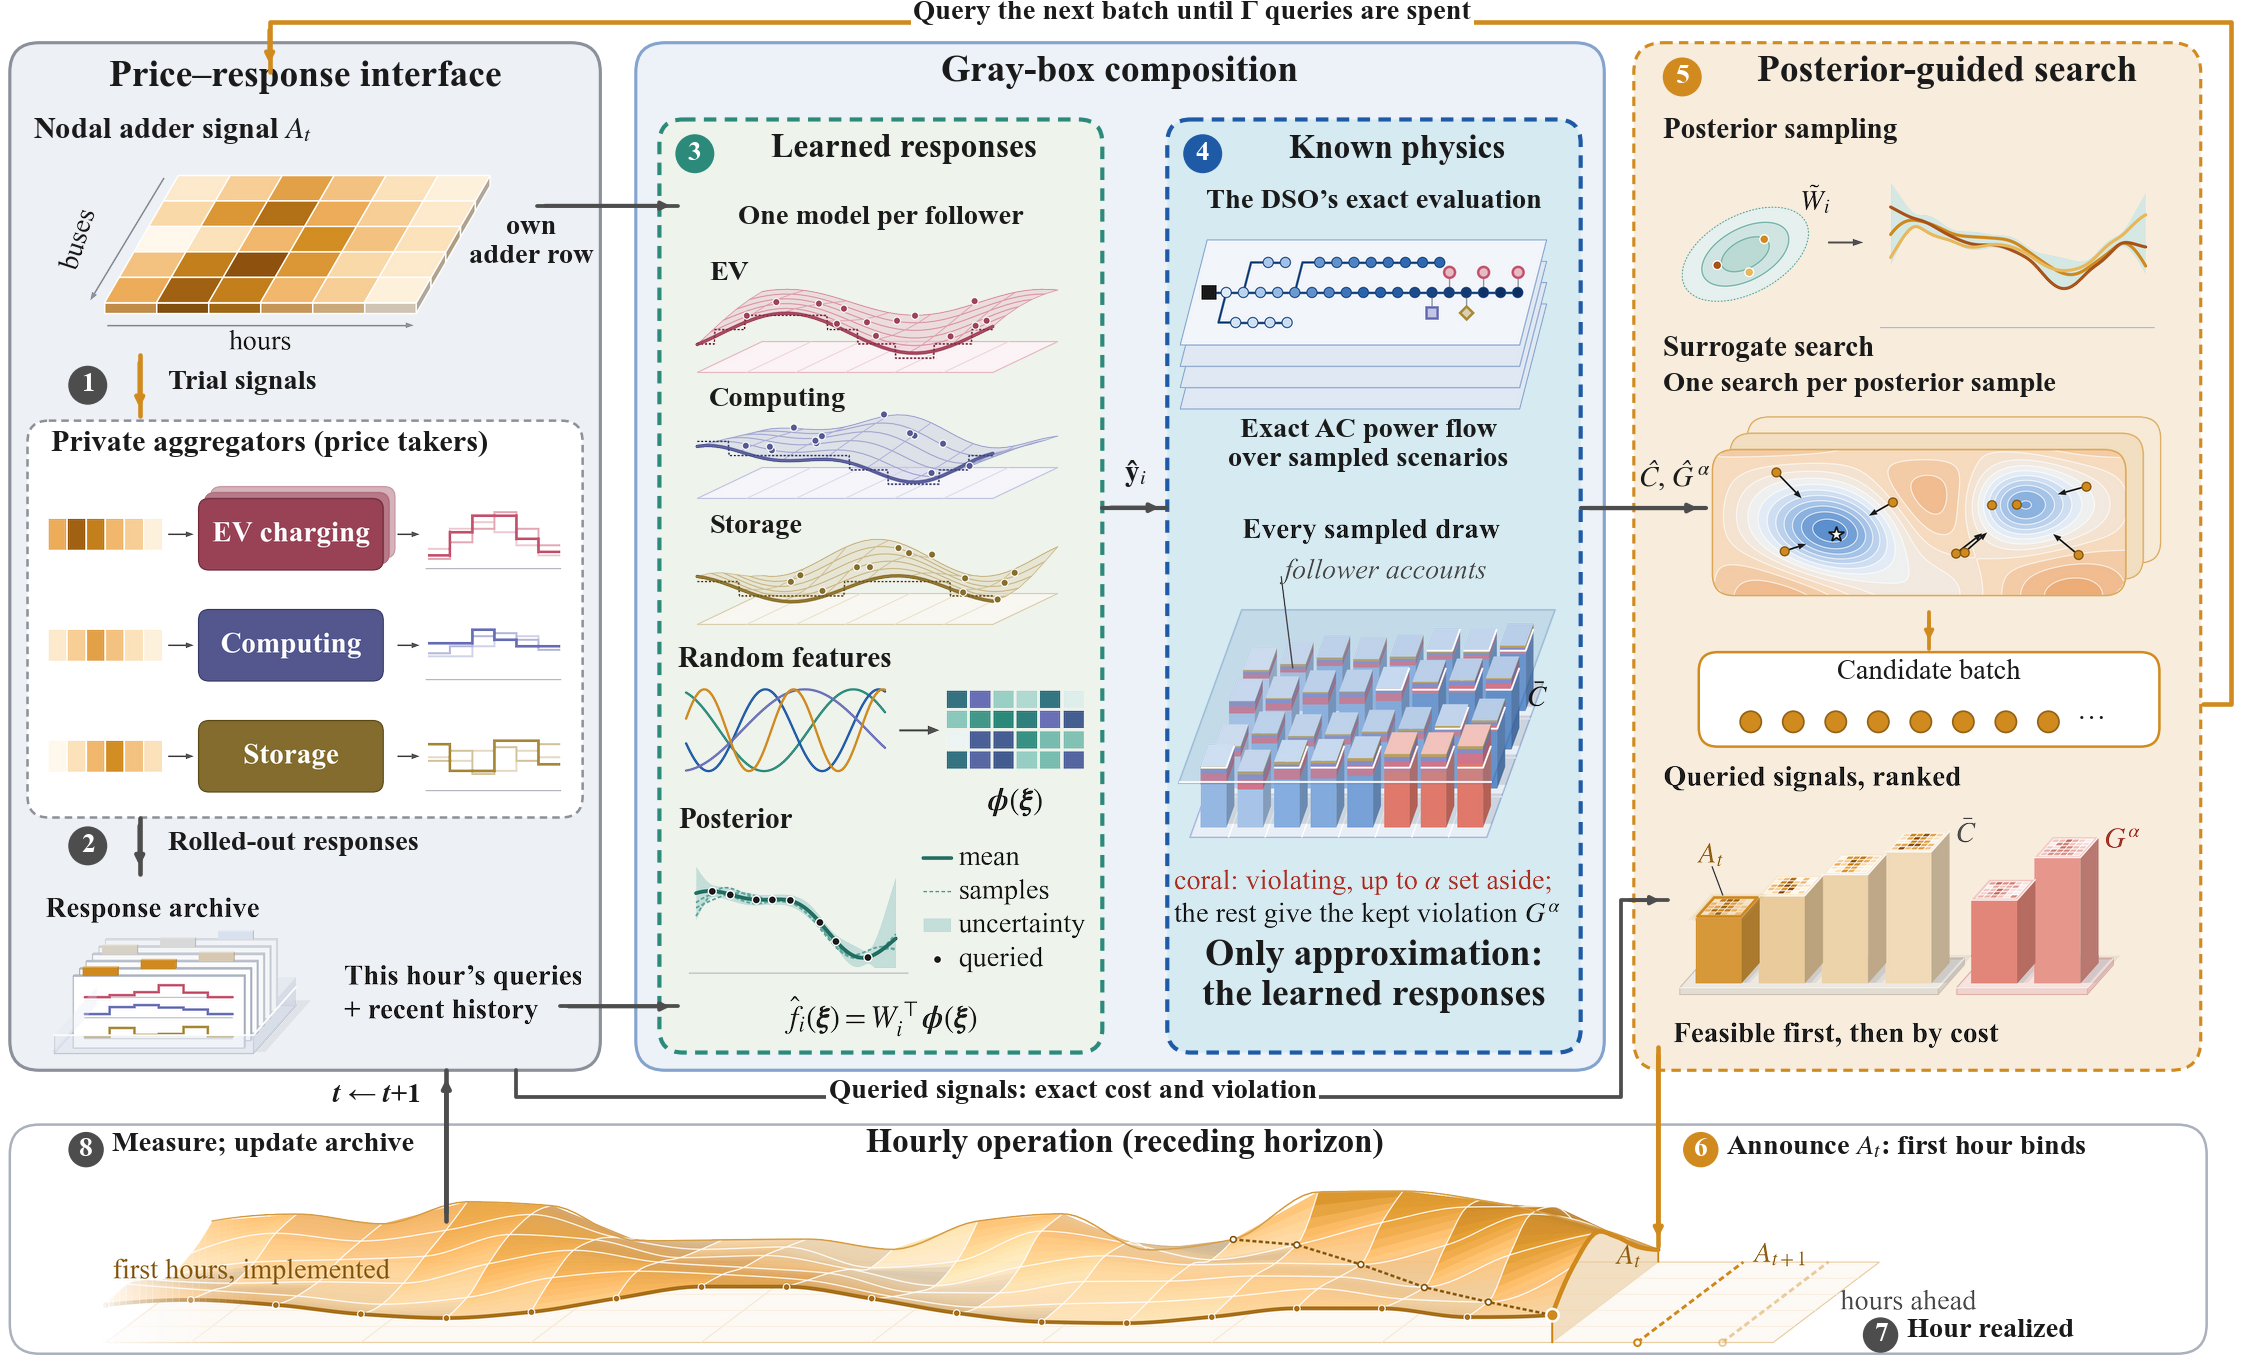

In [9]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch
from PIL import Image

plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman"], "mathtext.fontset": "stix"})
fig = plt.figure(figsize=(W / 25.4, H / 25.4), dpi=300)
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, W)
ax.set_ylim(H, 0)                                               # y 往下，和 PPT 一样
ax.axis("off")
for z, s_ in enumerate(SHAPES):
    k = s_["kind"]
    if k == "box":
        ax.add_patch(FancyBboxPatch((s_["x"], s_["y"]), s_["w"], s_["h"],
                                    boxstyle=f"round,pad=0,rounding_size={s_['r']}" if s_["r"] else "square,pad=0",
                                    fc=s_["fill"] or "none", ec=s_["line"] or "none", lw=s_["lw"],
                                    ls=(0, (3, 2)) if s_["dash"] else "-", zorder=z))
    elif k == "text":
        ha = {"l": "left", "c": "center", "r": "right"}[s_["align"]]
        x = s_["x"] + {"l": 0, "c": s_["w"] / 2, "r": s_["w"]}[s_["align"]]
        label = s_["label"].replace("\\bm{", "\\boldsymbol{")
        ax.text(x, s_["y"] + 0.15, label, fontsize=s_["size"], color=s_["color"], ha=ha, va="top",
                fontweight="bold" if s_["bold"] else "normal", linespacing=1.25, zorder=z,
                bbox=dict(fc=s_["bg"], ec="none", pad=0.6) if s_["bg"] else None)
    elif k == "arrow":
        xs, ys = zip(*s_["pts"])
        ax.plot(xs[:-1] + (xs[-1],), ys[:-1] + (ys[-1],), color=s_["color"], lw=s_["lw"], zorder=z,
                solid_capstyle="round")
        if s_["head"]:
            ax.add_patch(FancyArrowPatch(s_["pts"][-2], s_["pts"][-1], arrowstyle="-|>", mutation_scale=4,
                                         color=s_["color"], lw=s_["lw"], zorder=z))
    elif k in ("badge", "dot"):
        ax.add_patch(Circle((s_["cx"], s_["cy"]), s_["d"] / 2, fc=s_["color"],
                            ec=s_.get("line") or "none", lw=0.4, zorder=z))
        if k == "badge":
            ax.text(s_["cx"], s_["cy"], str(s_["n"]), color="white", fontsize=6.6, fontweight="bold",
                    ha="center", va="center", zorder=z)
    elif k == "pic":
        im = Image.open(s_["path"])
        h = s_["w"] * im.height / im.width
        ax.imshow(im, extent=(s_["x"], s_["x"] + s_["w"], s_["y"] + h, s_["y"]), zorder=z,
                  interpolation="lanczos")
ax.set_xlim(0, W)
ax.set_ylim(H, 0)
plt.show()

## 4. 附：用同样的方法做一页幻灯片

组会的 PPT 也是这样生成的：每页写成一串“框、字、图片”。下面这页是其中一种版式：标题、一张带柔和阴影的白卡片、卡片上放一个组件。阴影 python-pptx 也没有现成的写法，同样直接改 XML。字体用的是苹方，在 Windows 上把 `FONT_CN` 改成 `"Microsoft YaHei"`。

In [10]:
from pptx.util import Inches

FONT_CN = "PingFang SC"                                         # Windows 上改成 "Microsoft YaHei"
deck = Presentation()
deck.slide_width, deck.slide_height = Inches(13.333), Inches(7.5)   # 16:9
page = deck.slides.add_slide(deck.slide_layouts[6])
page.background.fill.solid()
page.background.fill.fore_color.rgb = rgb("#F6F4F0")               # 浅米白底


def words(x, y, w, h, s, size, color, bold=False):
    tb = page.shapes.add_textbox(Inches(x), Inches(y), Inches(w), Inches(h))
    tf = tb.text_frame
    tf.margin_left = tf.margin_right = tf.margin_top = tf.margin_bottom = 0
    r = tf.paragraphs[0].add_run()
    r.text = s
    r.font.size, r.font.bold, r.font.color.rgb = Pt(size), bold, rgb(color)
    r.font.name = FONT_CN
    ea = etree.SubElement(r._r.get_or_add_rPr(), qn("a:ea"))   # 中文字体单独设一遍
    ea.set("typeface", FONT_CN)
    return tb


words(0.75, 0.45, 6, 0.3, "第 3 步 · 用 Python 画组件", 12.5, "#B4700F", bold=True)
words(0.75, 0.76, 11.8, 0.6, "每个组件，都是一张单独的小图", 29, "#1E2B3A", bold=True)

card = page.shapes.add_shape(MSO_SHAPE.ROUNDED_RECTANGLE, Inches(3.4), Inches(1.9), Inches(6.5), Inches(4.4))
card.adjustments[0] = 0.03
card.fill.solid()
card.fill.fore_color.rgb = rgb("#FFFFFF")
card.line.color.rgb = rgb("#E2DED7")
card.line.width = Pt(0.5)
effects = etree.SubElement(card._element.spPr, qn("a:effectLst"))       # 柔和的投影
shadow = etree.SubElement(effects, qn("a:outerShdw"), blurRad=str(int(0.14 * 914400)),
                          dist=str(int(0.04 * 914400)), dir="5400000", algn="t", rotWithShape="0")
color = etree.SubElement(shadow, qn("a:srgbClr"), val="1C2B3A")
etree.SubElement(color, qn("a:alpha"), val="20000")

page.shapes.add_picture("out/fig3_12_ranked_signals.png", Inches(3.75), Inches(2.15), height=Inches(3.9))
words(12.2, 7.05, 0.4, 0.25, "14", 10, "#8592A0")                    # 页码
deck.save("out/一页幻灯片.pptx")
print("已保存 out/一页幻灯片.pptx")

已保存 out/一页幻灯片.pptx
